# Basic Model for Count Data
We start by looking at models for *count* data. This type of data has several key properties that make the standard linear model inappropriate. The main concern is that counts cannot go below 0. As such, the model must be bounded to only produce predictions from 0 to (in principle) $\infty$. Counts can also only be whole numbers. However, many discrete distributions allow their parameters to take on fractional values, meaning that we can model the *average count* without must additional concern. This actually makes count data more amenable to linear modelling than binary data. The key difference is that, particularly for low numbers of counts, the marginal distribution will be highly skewed. Furthermore, in many real-world applications there may be an excess of 0's, depending upon the rarity of the event being counted. As such, choice of distribution is key.



## Distribution
The most common distribution used for count data is the Poisson. Other distributions, such as the *negative binomial*, are also used, but the Poisson remains the *default* choice for count data and is therefore the distribution we will focus on.

$$
\begin{align*}
    E(y_{i})          &= \mu_{i} = \lambda_{i} \\
    \text{Var}(y_{i}) &= \phi V(\mu_{i}) = \lambda_{i} 
\end{align*}
$$


It is important at this stage to distinguish between the type of counts that can be modelled with binomial logistic regression and the type of counts we are focussing on this week. Under a binomial model, the counts are based on the number of success in a *fixed number of trials*. On each trial, we can have either success or failure

:::{admonition} Binomial Versus Poisson Counts
:class: tip
There is actually a deeper connection between the binomial and Poisson distributions, which may help with understanding their differences. There can, on the face of it, be ambiguities around whether something can be modelled as either binomial or Poisson. For instance, we could decided, when counting the number of customers who enter a shop over the course of an hour, to divide that time up into minutes and call it "60 trials". On each trial, a customer either enters or they do not. The binomial would then be perfectly suitable. However, what if 2 or more customers enter within the same minute? This counts as a "success" but is not really distinguished correctly from only 1 customer entering. We could perhaps make the time intervals even smaller, perhaps down to the *second* or *millisecond*. As we do this, we are tending the number of trials to $n \rightarrow \infty$, which will then make the probability of the event occurring on each trial smaller and smaller $p \rightarrow 0$. And what happens with a binomial distribution as $n \rightarrow \infty$ and $p \rightarrow 0$? It actually converges on a Poisson distribution. So there is a deeper connection here. As the definition of "trial" becomes less well-defined due to stretching the counting over some interval (such as time or space), the binomial will simply turn into the Poisson, where our interest turns to the average count during that interval, rather than average "successes" in a sequence of well-defined trials. 
:::

### Overdispersion
... For cases of *overdispersion*, this involves estimating a value for $\phi$ which will scale the Poisson variance up or down. This is referred to as a *quasi-Poisson* model in `R` because, technically, the distribution is *not* Poisson if the variance does not equal the mean.

### Zero-inflation
... In this case, we can use *zero-inflated* models. These approaches effectively fit two models, one the captures the excessive zeros and one that captures the counts after the zeros have been accommodated. This is therefore a type of *mixture model*, where the marginal distribution of the data concerns two separate processes, one that governs the probability of getting a 0 and one that governs the probability of getting anything above 0. We will see examples of this later.

## Link Function



### Lower Bound

### Multiplicative Effects
The other consequence of the log link is that, on the scale of the link function, we are not modelling a consistent change in the counts for each unit increase of the predictor. For example, under standard regression, we might predict that as the predictor increases the average count drops by 5. On the log scale, we are instead modelling change as a *proportion* of the previous value. So, rather than the average count dropping by 5 for each unit increase, it might instead drop by 20% of the previous value. 

This has a number of desirable properties. Firstly, the average count can never drop below 0 because it simply flattens more and more the closer you get to 0. 

Some example predictions are given in the table below. Notice that linear regression reduces the prediction by 4 each time. The log-link instead reduces the prediction by 20% of the previous value each time. Eventually, the linear regression model will cross 0 and start predicting impossible counts. The log-link will instead slowly curve gradually towards 0, but will never reach it. This is visualised in the plot below the table.


| Predictor (x) | Linear regression | Log-link regression |
|---:|---:|---:|
| 0 | 20 | 20.00 |
| 1 | 16 | 16.00 |
| 2 | 12 | 12.80 |
| 3 | 8 | 10.24 |
| 4 | 4 | 8.19 |
| 5 | 0 | 6.55 |
| 6 | -4 | 5.24 |
| 7 | -8 | 4.19 |
| 8 | -12 | 3.36 |


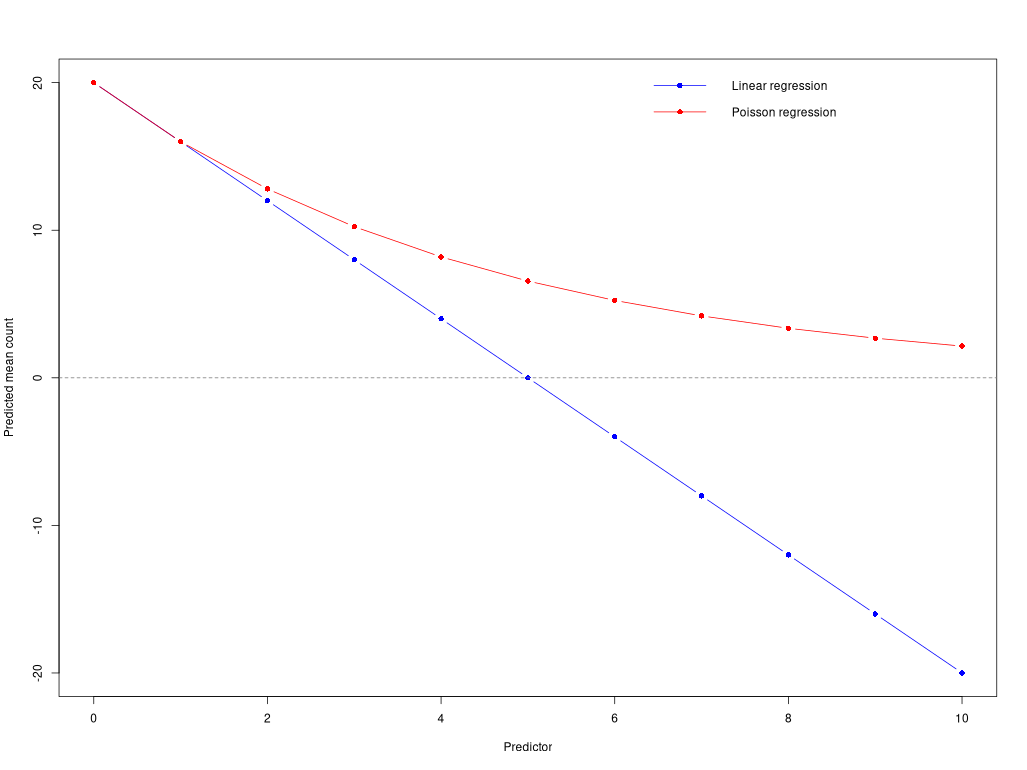

In [2]:
# Predictor values
x <- 0:10

# Predicted mean counts
linear <- 20 - 4*x
poisson <- 20 * 0.8^x

# Plot
plot(x, linear, type = "b", pch = 16, col = "blue",
     ylim = range(c(linear, poisson)),
     xlab = "Predictor",
     ylab = "Predicted mean count")

lines(x, poisson, type = "b", pch = 16, col = "red")

abline(h = 0, lty = 2, col = "grey50")

legend("topright",
       legend = c("Linear regression", "Poisson regression"),
       col = c("blue", "red"),
       lty = 1, pch = 16, bty = "n")


## Parameter Estimation


:::{tip .simple icon=false} What You Now Know
In this section, we have discussed the basic Poisson regression model for count data. After reading this section, you should have a good sense of:
- ...
- ...
:::